# 5 · Step size and exploration

The report ends on a regret. Its Q-learner had fallen short of the planners, and the suspected
cause was the missing exploration rate:

> "implementing it with non-zero ϵ would no doubt improve the performance of Q-learning on both
> classes of MDPs. But that this assignment were due a few days hence!"

This notebook spends the few days. It finds that

1. the 2014 failure had nothing to do with ϵ. It is fully explained by the step size, and can be
   predicted, cell for cell, without running the learner at all;
2. for an agent that has to choose its own experience, exploration does matter, though the best
   explorer on the grid world turns out to be a greedy one;
3. the two MDPs of the report want opposite step sizes, for a reason that can be measured.

In [1]:
import time

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from IPython.display import Markdown, display

import mdplab as ml
from mdplab import plotting as mp
from mdplab import report
from mdplab.gridworld import ARROWS

mp.use_style()
pd.options.display.float_format = "{:,.2f}".format

world = ml.GridWorld.report_figure1()
mdp = world.mdp
free = world.free
states = np.arange(mdp.n_states)
scorer = ml.PolicyScorer(mdp)
V_star, Q_star = scorer.V_star, scorer.Q_star


def costly_mistakes(Q):
    """Mask (runs, states): cells where the greedy action gives up more than 1 in value."""
    policies = Q.argmax(axis=-1)
    return ((V_star - Q_star[states, policies]) > 1.0) & free

## Q-learning is value iteration with a slow clock

Notebook 3 rebuilt the 2014 learner: every state-action pair visited equally often, 5,600 times
each, with step size $\alpha_n = 1/n$ on the $n$-th visit. Each update is

$$Q(s,a) \leftarrow Q(s,a) + \alpha_n\,\bigl(r + \gamma \max_{a'} Q(s',a') - Q(s,a)\bigr).$$

Average the bracket over the random next state and it becomes $(\mathcal{T}Q)(s,a) - Q(s,a)$, where
$\mathcal{T}$ is exactly the backup that value iteration applies. So on average one round of
updates moves $Q$ a fraction $\alpha_n$ of the way towards what one sweep of value iteration
would give:

$$Q_n \approx Q_{n-1} + \alpha_n\,(\mathcal{T}Q_{n-1} - Q_{n-1}) \quad + \text{noise}.$$

After $n$ rounds, the learner has travelled a total distance
$\tau(n) = \alpha_1 + \alpha_2 + \dots + \alpha_n$ along the path that value iteration follows. Call
$\tau$ the learner's **effective time**: roughly, the number of value-iteration sweeps its
experience has been worth. The step-size schedule is the clock that converts visits into
effective time, and the clocks differ enormously:

In [2]:
schedules = {
    "1/n": ml.harmonic(),
    "1/n^0.9": ml.polynomial(0.9),
    "1/n^0.8": ml.polynomial(0.8),
    "1/n^0.7": ml.polynomial(0.7),
    "1/n^0.6": ml.polynomial(0.6),
    "1/n^0.5": ml.polynomial(0.5),
    "0.1": ml.constant(0.1),
    "0.01": ml.constant(0.01),
}


def effective_time(schedule, n):
    """tau(1), ..., tau(n) for a step-size schedule."""
    return np.cumsum(schedule(np.arange(1, n + 1)))


clock = pd.DataFrame(
    {name: [effective_time(s, 10**6)[n - 1] for n in (100, 5600, 10**6)] for name, s in schedules.items()},
    index=pd.Index([100, 5600, 10**6], name="visits per pair"),
).T
clock.columns = [f"effective time after {n:,} visits" for n in clock.columns]
clock

,effective time after 100 visits,"effective time after 5,600 visits","effective time after 1,000,000 visits"
1/n,5.19,9.21,14.39
1/n^0.9,6.43,14.27,30.38
1/n^0.8,8.13,23.66,74.81
1/n^0.7,10.51,41.62,207.54
1/n^0.6,13.85,76.98,626.02
1/n^0.5,18.59,148.21,"1,998.54"
0.1,10.00,560.00,"100,000.00"
0.01,1.00,56.00,"10,000.00"


With $\alpha_n = 1/n$ effective time grows like the logarithm of the number of visits. The 5,600
visits of 2014 bought about 9 units, and a million would have bought 14. Notebook 2 showed that
value iteration needs 26 sweeps before its greedy policy on this world is the optimal one.

## The 2014 budget, with other clocks

First the experiment: the same 5,600 uniform visits per pair, 30 independent runs for each step
size, scored by how much value the learned policy gives up against the optimum (averaged over
starting cells) and by its costly mistakes, as defined in notebook 3.

In [3]:
budget = 5600
rows_out, final = [], {}
for name, schedule in schedules.items():
    runs = ml.synchronous_q_learning(mdp, budget, alpha=schedule, n_runs=30, seed=5)
    gap = scorer(runs.Q)["value_gap"]
    mistakes = costly_mistakes(runs.Q)
    final[name] = gap
    rows_out.append({
        "step size": name,
        "effective time": effective_time(schedule, budget)[-1],
        "value given up (mean)": gap.mean(),
        "value given up (worst run)": gap.max(),
        "costly mistakes per run": mistakes.sum(axis=1).mean(),
        "runs without a costly mistake (of 30)": int((mistakes.sum(axis=1) == 0).sum()),
    })
at_budget = pd.DataFrame(rows_out).set_index("step size")
at_budget

,effective time,value given up (mean),value given up (worst run),costly mistakes per run,runs without a costly mistake (of 30)
step size,,,,,
1/n,9.21,5.27,5.39,2.97,0
1/n^0.9,14.27,0.87,1.31,1.33,0
1/n^0.8,23.66,0.63,0.66,0.97,1
1/n^0.7,41.62,0.00,0.01,0.00,30
1/n^0.6,76.98,0.01,0.02,0.00,30
1/n^0.5,148.21,0.01,0.06,0.00,30
0.1,560.00,0.38,3.69,0.27,23
0.01,56.00,0.01,0.04,0.00,30


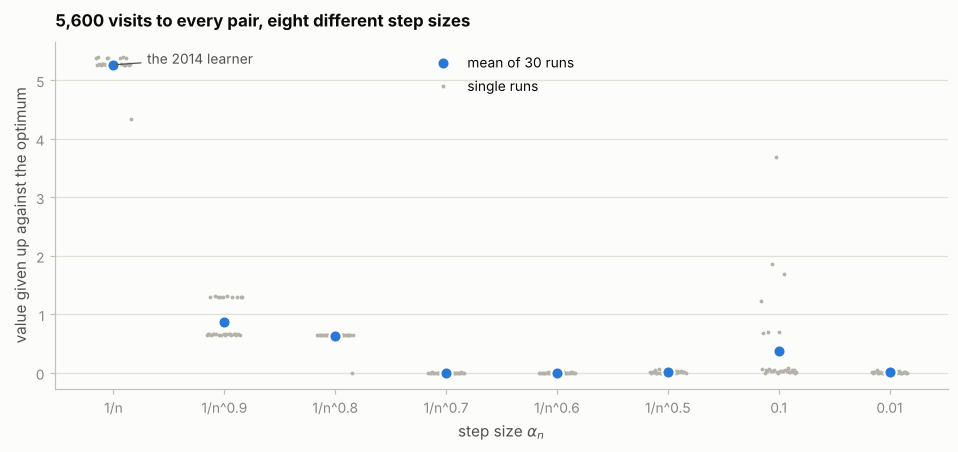

In [4]:
fig, ax = plt.subplots(figsize=(8.6, 4))
names = list(schedules)
for i, name in enumerate(names):
    ax.plot(np.full(30, i) + np.linspace(-0.16, 0.16, 30), final[name], ".", color=mp.GREY, markersize=5, markeredgewidth=0)
ax.plot(range(len(names)), [final[n].mean() for n in names], "o", color=mp.SERIES[0], markersize=8, label="mean of 30 runs")
ax.plot([], [], ".", color=mp.GREY, markersize=8, label="single runs")
ax.annotate("the 2014 learner", (0, final["1/n"].mean()), xytext=(22, 4), textcoords="offset points", fontsize=9, color=mp.INK_SECONDARY, va="center",
            arrowprops=dict(arrowstyle="-", color=mp.INK_SECONDARY, linewidth=0.8))
ax.set_xticks(range(len(names)), names)
ax.set(xlabel=r"step size $\alpha_n$", ylabel="value given up against the optimum", title="5,600 visits to every pair, eight different step sizes")
ax.grid(axis="x", visible=False)
ax.legend(loc="upper center")
mp.savefig(fig, "05_step_sizes_at_budget");

The $1/n$ learner is the worst of the eight. Every polynomial schedule with an exponent of 0.7 or
less finds a policy that gives up essentially nothing, with the same data. The ordering follows
the effective time in the first column almost perfectly, until the steps become so large that
noise takes over (the constant 0.1).

## One curve for all step sizes

If effective time is the right way to think about this, then learners with different step sizes
should look alike once their progress is plotted against $\tau$ instead of against the number of
visits. And they should all follow the noise-free version of the process, the flow
$\mathrm{d}Q/\mathrm{d}\tau = \mathcal{T}Q - Q$, which can be integrated directly from the model
without sampling anything.

In [5]:
def flow(tau_max=45.0, dt=0.005, record_every=20):
    """Integrate dQ/dtau = TQ - Q from Q = 0.  Returns times, value gaps and the mistake mask over time."""
    Q = np.zeros((mdp.n_states, mdp.n_actions))
    taus, gaps, masks = [], [], []
    for k in range(1, int(tau_max / dt) + 1):
        Q += dt * (mdp.q_values(Q.max(axis=1)) - Q)
        if k % record_every == 0:
            taus.append(k * dt)
            gaps.append(scorer(Q)["value_gap"][0])
            masks.append(costly_mistakes(Q))
    return np.array(taus), np.array(gaps), np.array(masks)


flow_tau, flow_gap, flow_mask = flow()

curves = {}
start = time.perf_counter()
for name in ("1/n", "1/n^0.9", "1/n^0.7", "1/n^0.5", "0.01"):
    runs = ml.synchronous_q_learning(mdp, 30_000, alpha=schedules[name], n_runs=8, seed=1, scorer=scorer, n_checkpoints=45)
    curves[name] = (runs.steps, effective_time(schedules[name], 30_000)[runs.steps - 1], runs.history["value_gap"].mean(axis=1))
print(f"{time.perf_counter() - start:.0f} s")

20 s


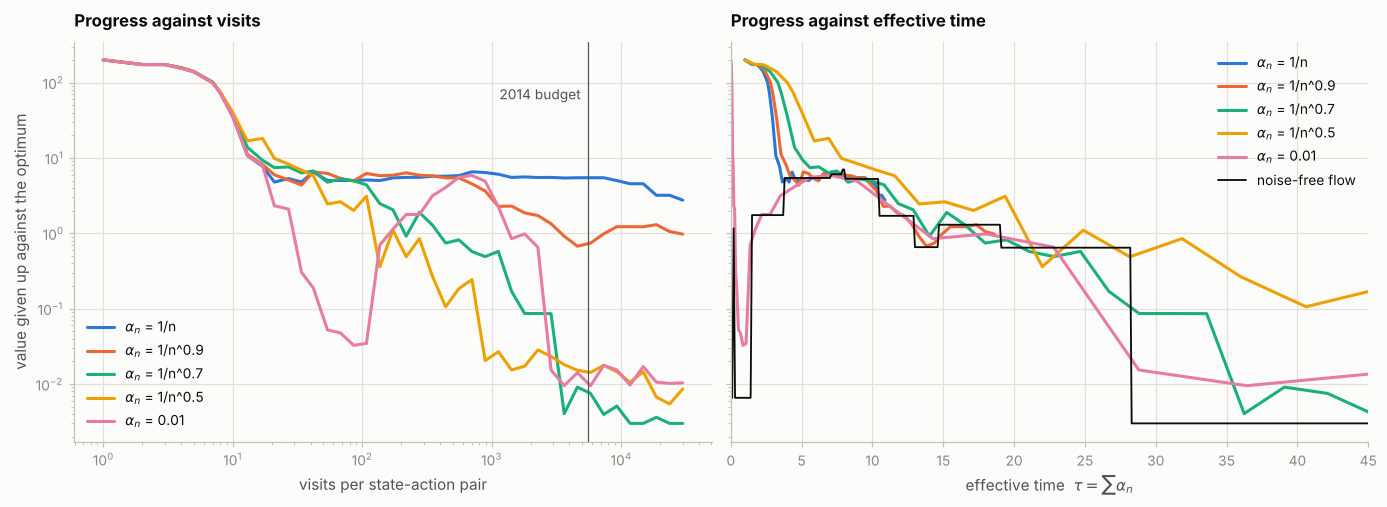

In [6]:
fig, axes = plt.subplots(1, 2, figsize=(12.5, 4.5), sharey=True)
floor = 3e-3
for (name, (n, tau, gap)), colour in zip(curves.items(), mp.SERIES):
    axes[0].plot(n, np.maximum(gap, floor), color=colour, label=rf"$\alpha_n$ = {name}")
    axes[1].plot(tau, np.maximum(gap, floor), color=colour, label=rf"$\alpha_n$ = {name}")
axes[1].plot(flow_tau, np.maximum(flow_gap, floor), color=mp.INK, linewidth=1.2, label="noise-free flow")
axes[0].axvline(budget, color=mp.INK_SECONDARY, linewidth=0.8)
axes[0].annotate("2014 budget", (budget, 60), xytext=(-5, 0), textcoords="offset points", ha="right", fontsize=9, color=mp.INK_SECONDARY)
axes[0].set(xscale="log", yscale="log", xlabel="visits per state-action pair", ylabel="value given up against the optimum", title="Progress against visits")
axes[1].set(xlim=(0, 45), xlabel=r"effective time  $\tau = \sum \alpha_n$", title="Progress against effective time")
axes[0].legend(loc="lower left")
axes[1].legend(loc="upper right")
mp.savefig(fig, "05_effective_time");

On the left the five learners are far apart. On the right, against effective time, they follow one
path, the one traced by the noise-free flow (black): a staircase whose every step is one cell of
the grid changing its greedy move. The learners differ only in how fast they travel along it and
in how much noise they carry. The bigger its recent steps, the more a learner jitters around the
flow.

The path is not a steady descent, and its shape explains a good deal. For the first unit of
effective time the greedy policy is nearly optimal: all the learner knows by then is which moves
risk a pit, and avoiding those is most of what the optimal policy does. Then the goal's reward
arrives, first along the short routes that run beside the pits, and the policy gets *worse*. It
recovers only as the value of each long, safe detour catches up, one cell at a time. The learner
with $\alpha_n = 0.01$, whose steps are small enough to resolve the early part, shows the dip
and the rise in the left panel. The 2014 learner spent nearly all of its 5,600 visits on the
plateau that follows.

## Predicting Figure 1b without running the learner

The flow says, for each cell, the effective time after which its greedy move is the right one.

In [7]:
last_wrong = {}
for s in np.flatnonzero(free):
    wrong_at = np.flatnonzero(flow_mask[:, s])
    if wrong_at.size and flow_tau[wrong_at[-1]] > 3:
        last_wrong[world.cell(s)] = flow_tau[wrong_at[-1]]


def visits_needed(name, tau):
    """Visits per pair after which a schedule's effective time exceeds tau."""
    if name == "1/n":
        return float(np.exp(tau - np.euler_gamma))  # harmonic numbers: H_n ~ ln n + 0.577
    return float(np.searchsorted(effective_time(schedules[name], 10**7), tau) + 1)


flip = pd.DataFrame(
    [
        {
            "cell": cell,
            "optimal move": ARROWS[Q_star[world.state(*cell)].argmax()],
            "wrong until effective time": tau,
            "visits needed with 1/n": visits_needed("1/n", tau),
            "visits needed with 1/n^0.7": visits_needed("1/n^0.7", tau),
        }
        for cell, tau in sorted(last_wrong.items(), key=lambda kv: kv[1])
    ]
).set_index("cell")
flip.assign(**{
    "wrong until effective time": flip["wrong until effective time"].map("{:.1f}".format),
    "visits needed with 1/n": flip["visits needed with 1/n"].map("{:,.0f}".format),
    "visits needed with 1/n^0.7": flip["visits needed with 1/n^0.7"].map("{:,.0f}".format),
})

,optimal move,wrong until effective time,visits needed with 1/n,visits needed with 1/n^0.7
cell,,,,
"(6, 6)",←,8.0,"1,674",50
"(0, 6)",←,10.4,"18,449",98
"(4, 3)",←,12.9,"224,759",174
"(6, 1)",↓,19.0,"100,210,581",521
"(5, 0)",←,28.2,"991,797,048,504","1,688"


In [8]:
tau_2014 = effective_time(schedules["1/n"], budget)[-1]
predicted = sorted(cell for cell, tau in last_wrong.items() if tau > tau_2014 and flow_mask[np.searchsorted(flow_tau, tau_2014), world.state(*cell)])
tau_done = max(last_wrong.values())
n_done = visits_needed("1/n", tau_done)
rate_2014 = report.TABLE_GRIDWORLD.loc["Q-learning", "iterations"] / report.TABLE_GRIDWORLD.loc["Q-learning", "seconds"]  # updates per second
years = n_done * 224 / rate_2014 / 3.156e7
display(Markdown(
    f"The 2014 learner stopped at effective time **{tau_2014:.1f}**. The cells the flow still has wrong at that moment are "
    f"**{', '.join(map(str, predicted))}**: the three red arrows of Figure 1b, and no others.\n\n"
    f"The last cell to come right does so at effective time {tau_done:.1f}. A step size of $1/n$ reaches that after about "
    f"**{n_done:.1e} visits to every pair**. At the speed of the 2014 code that is roughly **{years:,.0f} years** of computing. "
    f"With $1/n^{{0.7}}$ it takes {visits_needed('1/n^0.7', tau_done):,.0f} visits."
))

The 2014 learner stopped at effective time **9.2**. The cells the flow still has wrong at that moment are **(0, 6), (4, 3), (6, 1)**: the three red arrows of Figure 1b, and no others.

The last cell to come right does so at effective time 28.2. A step size of $1/n$ reaches that after about **9.9e+11 visits to every pair**. At the speed of the 2014 code that is roughly **605 years** of computing. With $1/n^{0.7}$ it takes 1,688 visits.

So the report's description of what it saw was accurate: the learner "ceased to learn". After the
first few hundred visits, a $1/n$ learner needs to multiply its experience by $e \approx 2.7$ for
every further unit of effective time, and the policy it holds while it creeps along is a snapshot
of value iteration around its tenth sweep. That snapshot is Figure 1b.

The order in which the cells come right is itself informative. The last two, (6, 1) and (5, 0),
are the cells where the optimal move is to push against a wall and wait for a slip. The value of
waiting feeds back on itself nine times out of ten, so it converges at the slowest rate of any
quantity in this world. Notebook 6 meets the same two cells again as the reason value iteration
needs 159 sweeps here.

This behaviour of $1/n$ is known to theory. Even-Dar and Mansour (2003) showed that with a linear
step size the time Q-learning needs grows exponentially in the horizon $1/(1-\gamma)$, here 100,
while for $\alpha_n = 1/n^{\omega}$ with $\omega < 1$ it grows only polynomially. The staircase
above is that theorem at work on one small grid.

## The price of large steps

If a slowly decaying step size travels faster, why not make it constant and large? Because the
same steps that move the estimate also shake it. Averaged over many runs, the error of a learned
table splits into a part that is the same in every run (bias: the learner has not got there yet)
and a part that differs from run to run (noise).

One refinement matters. A policy only compares actions within a state, so what has to be right is
not $Q(s,a)$ itself but the *advantage* of each action over the others in its state,
$Q(s,a) - \operatorname{mean}_{a'} Q(s,a')$. An error shared by all actions of a state does no harm.

In [9]:
def bias_and_noise(m, visits, schedule, n_runs=24, seed=0):
    """Root-mean-square bias and noise of learned values and of learned advantages."""
    sc = ml.PolicyScorer(m)
    learned = ml.synchronous_q_learning(m, visits, alpha=schedule, n_runs=n_runs, seed=seed).Q
    Q = learned[:, m.active]
    truth = sc.Q_star[m.active]
    centre = lambda q: q - q.mean(axis=-1, keepdims=True)
    rms = lambda x: float(np.sqrt(np.mean(x**2)))
    top_two = np.sort(truth, axis=1)[:, -2:]
    return {
        "value bias": rms(Q.mean(axis=0) - truth),
        "value noise": rms(Q.std(axis=0)),
        "advantage bias": rms(centre(Q).mean(axis=0) - centre(truth)),
        "advantage noise": rms(centre(Q).std(axis=0)),
        "typical gap between the two best actions": float(np.median(top_two[:, 1] - top_two[:, 0])),
        "value given up by the policy": float(sc(learned)["value_gap"].mean()),
    }


grid_rows = {name: bias_and_noise(mdp, budget, schedules[name]) for name in ("1/n", "1/n^0.7", "1/n^0.5", "0.1")}
pd.DataFrame(grid_rows).T.rename_axis("step size (grid world, 5,600 visits)")

,value bias,value noise,advantage bias,advantage noise,typical gap between the two best actions,value given up by the policy
"step size (grid world, 5,600 visits)",,,,,,
1/n,108.76,8.11,18.46,2.07,1.97,5.45
1/n^0.7,1.15,1.70,0.81,1.48,1.97,0.01
1/n^0.5,0.90,3.92,0.86,3.42,1.97,0.02
0.1,2.75,11.90,2.37,10.19,1.97,0.61


On the grid world the $1/n$ learner's problem is bias. Its values are off by more than a hundred,
and, worse, unevenly: the advantages are off by far more than the gap that separates the best move
from the runner-up. Its noise is small by comparison. A learner with $1/n^{0.7}$ has little of
either. With a constant 0.1 the bias is small as well, but the noise is now several times larger
than the gap between good moves, and the policy flickers.

## Learning online: where exploration comes in

Everything so far gave the learner its experience on a plate, every pair visited equally. That is
how the 2014 learner worked, and it is why ϵ was beside the point. The usual setting is harder.
The agent starts somewhere, acts, and only learns about what it does. Now the choice of actions
matters.

Below, an agent learns the 7 × 8 world online for 200,000 moves, about a sixth of the 2014 budget.
Episodes start in a random cell. It acts greedily except that with probability ϵ it picks a
random move. Eight agents are trained for each combination of ϵ and step size.

In [10]:
online_steps = 200_000
epsilons = [0.0, 0.05, 0.2, 1.0]
online_alphas = {"1/n": ml.harmonic(), "1/n^0.7": ml.polynomial(0.7), "0.1": 0.1}
grid_gap = pd.DataFrame(index=pd.Index(epsilons, name="ϵ"), columns=pd.Index(list(online_alphas), name="step size"), dtype=float)
grid_untried = grid_gap.copy()
start = time.perf_counter()
for name, alpha in online_alphas.items():
    for eps in epsilons:
        agent = ml.td_control(mdp, online_steps, epsilon=eps, alpha=alpha, n_runs=8, seed=1, scorer=scorer, n_checkpoints=4, max_episode_steps=1000)
        grid_gap.loc[eps, name] = agent.history["value_gap"][-1].mean()
        grid_untried.loc[eps, name] = (agent.visits[:, free] == 0).mean()
print(f"{time.perf_counter() - start:.0f} s")

112 s


With ϵ = 0 the agent never tries 3% of the state-action pairs at all; with any ϵ > 0 it tries every one.

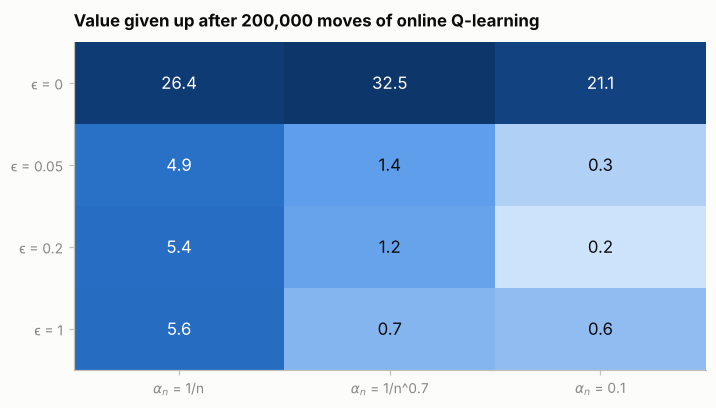

In [11]:
fig, ax = plt.subplots(figsize=(6.4, 3.6))
image = ax.imshow(np.log10(grid_gap.values.astype(float)), cmap=mp.SEQUENTIAL, aspect="auto")
for (i, j), value in np.ndenumerate(grid_gap.values.astype(float)):
    ax.text(j, i, f"{value:.1f}", ha="center", va="center", fontsize=11, color="white" if value > 3 else mp.INK)
ax.set_xticks(range(3), [rf"$\alpha_n$ = {n}" for n in online_alphas])
ax.set_yticks(range(4), [f"ϵ = {e:g}" for e in epsilons])
ax.grid(False)
ax.set_title("Value given up after 200,000 moves of online Q-learning")
mp.savefig(fig, "05_online_grid")
display(Markdown(
    f"With ϵ = 0 the agent never tries {grid_untried.loc[0.0].mean():.0%} of the state-action pairs at all; "
    f"with any ϵ > 0 it tries every one."
))

Both ingredients are needed, and they fail differently.

* **Top row: no exploration.** A greedy agent settles on the first workable routes it finds and
  never tries some moves at all. No step size rescues it. This is the lock-in the report had in
  mind, and for an agent of this kind the report's diagnosis would have been right.
* **Left column: step size 1/n.** However much the agent explores, even with every move random, it
  ends where the 2014 learner ended, giving up about 5. This is the failure the report actually
  had.
* **The rest.** With some exploration and a step size that does not die away too quickly, the loss
  is down to roughly 1 or below after a sixth of the 2014 budget.

### Exploring is not free, and ϵ is not the only way

A larger ϵ learns a better policy but spends more of its time doing foolish things, which in this
world means falling into pits. The second number that matters is therefore what the agent earned
*while* learning. Several ways of exploring are compared below, all with step size 0.1:

* constant ϵ;
* ϵ that decays over time, or with the number of visits to the current state;
* no ϵ at all, but with every $Q(s,a)$ initialised to 200, the largest return that is possible.
  A greedy agent with optimistic values tries each move until experience talks it down.

In [12]:
schemes = {
    "ϵ = 0.05": dict(epsilon=0.05),
    "ϵ = 0.2": dict(epsilon=0.2),
    "ϵ: 1 → 0.05 over the first half": dict(epsilon=ml.linear_decay(1.0, 0.05, online_steps // 2)),
    "ϵ = 20 / (20 + visits to state)": dict(epsilon=ml.visit_decay(20)),
    "ϵ = 100 / (100 + visits to state)": dict(epsilon=ml.visit_decay(100)),
    "greedy, values start at 0": dict(epsilon=0.0),
    "greedy, values start at 200": dict(epsilon=0.0, q_init=200.0),
}
rows_out = []
start = time.perf_counter()
for name, kwargs in schemes.items():
    agent = ml.td_control(mdp, online_steps, alpha=0.1, n_runs=12, seed=3, scorer=scorer, n_checkpoints=20, max_episode_steps=1000, **kwargs)
    episodes = agent.history["episodes"]
    weight = episodes / episodes.sum(axis=0)
    rows_out.append({
        "exploration": name,
        "value given up at the end": agent.history["value_gap"][-1].mean(),
        "reward per episode while learning": np.nansum(agent.history["episode_return"] * weight, axis=0).mean(),
        "episodes ending in a pit": np.nansum(agent.history["failure_rate"] * weight, axis=0).mean(),
    })
explore = pd.DataFrame(rows_out).set_index("exploration")
print(f"{time.perf_counter() - start:.0f} s")
explore.assign(**{"episodes ending in a pit": explore["episodes ending in a pit"].map("{:.1%}".format)})

72 s


,value given up at the end,reward per episode while learning,episodes ending in a pit
exploration,,,
ϵ = 0.05,0.43,189.41,2.6%
ϵ = 0.2,0.18,161.97,9.5%
ϵ: 1 → 0.05 over the first half,0.15,151.01,12.2%
ϵ = 20 / (20 + visits to state),1.66,193.68,1.6%
ϵ = 100 / (100 + visits to state),0.05,183.87,4.0%
"greedy, values start at 0",18.12,197.53,0.6%
"greedy, values start at 200",0.02,199.16,0.2%


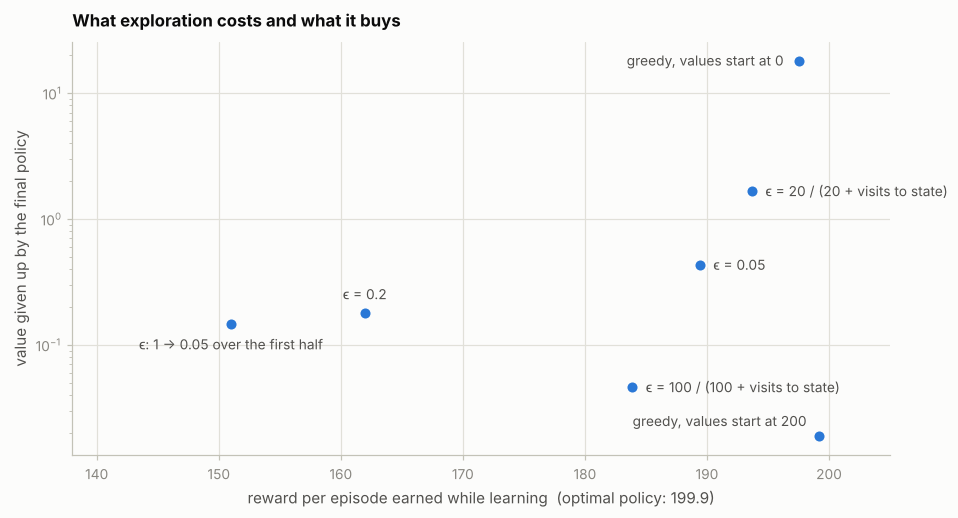

In [13]:
fig, ax = plt.subplots(figsize=(8.6, 4.6))
ax.plot(explore["reward per episode while learning"], explore["value given up at the end"], "o", color=mp.SERIES[0], markersize=8)
offsets = {
    "greedy, values start at 200": (-8, 10, "right"),
    "greedy, values start at 0": (-10, 0, "right"),
    "ϵ = 0.2": (0, 12, "center"),
    "ϵ: 1 → 0.05 over the first half": (0, -13, "center"),
}
for name, row in explore.iterrows():
    dx, dy, ha = offsets.get(name, (9, 0, "left"))
    ax.annotate(name, (row["reward per episode while learning"], row["value given up at the end"]), xytext=(dx, dy),
                textcoords="offset points", fontsize=9, color=mp.INK_SECONDARY, ha=ha, va="center")
ax.set(yscale="log", xlabel="reward per episode earned while learning  (optimal policy: 199.9)", ylabel="value given up by the final policy",
       title="What exploration costs and what it buys", xlim=(138, 205))
mp.savefig(fig, "05_exploration_tradeoff");

The best place to be is the bottom right: a good final policy, learned without much pain. The
agents with a constant or time-decaying ϵ line up along a trade-off, more exploration buying a
better policy at the cost of more falls. Tying ϵ to how often the current state has been visited
gets more for less: with 100 in the formula it beats ϵ = 0.2 on both axes.

The agent in the corner is the surprise. It never takes a random action, and it both learns the
best policy and earns the most along the way. Optimistic initial values make a greedy agent
explore *systematically*: every untried move looks like it is worth 200, so the agent tries it,
and when a move leads to a pit, once is usually enough. Random exploration has no such memory; it
walks into the same pit again and again for as long as ϵ is positive.

So "ϵ = 0" was never the sin. A greedy learner is a poor explorer when its initial values are
pessimistic (zero looks fine next to −0.01 per move, until the goal has been seen), and an
excellent one when they are optimistic.

## The elevator wants the opposite

On the grid world the cure for 2014 was a step size that decays more slowly. It is tempting to
call $1/n$ a bad choice and move on. The crazy elevator says otherwise.

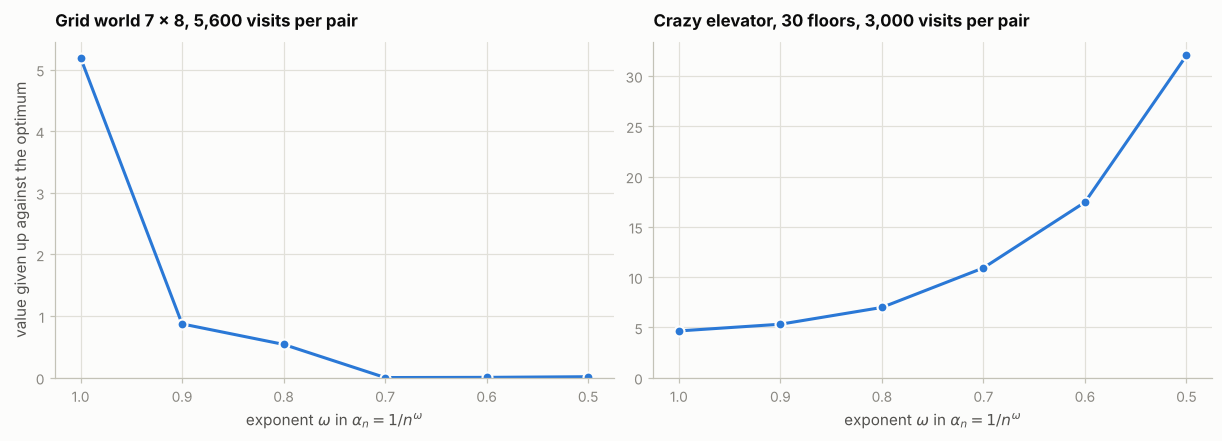

In [14]:
elevator = ml.crazy_elevator(30)
elevator_scorer = ml.PolicyScorer(elevator)
exponents = [1.0, 0.9, 0.8, 0.7, 0.6, 0.5]
gap_grid, gap_elevator = [], []
for omega in exponents:
    gap_grid.append(scorer(ml.synchronous_q_learning(mdp, budget, alpha=ml.polynomial(omega), n_runs=12, seed=2).Q)["value_gap"].mean())
    gap_elevator.append(elevator_scorer(ml.synchronous_q_learning(elevator, 3000, alpha=ml.polynomial(omega), n_runs=12, seed=2).Q)["value_gap"].mean())

fig, axes = plt.subplots(1, 2, figsize=(11, 3.9))
for ax, gaps, title in ((axes[0], gap_grid, "Grid world 7 × 8, 5,600 visits per pair"), (axes[1], gap_elevator, "Crazy elevator, 30 floors, 3,000 visits per pair")):
    ax.plot(exponents, gaps, "o-", color=mp.SERIES[0])
    ax.set(xlabel=r"exponent $\omega$ in $\alpha_n = 1/n^{\omega}$", title=title, ylim=(0, None))
    ax.invert_xaxis()
axes[0].set_ylabel("value given up against the optimum")
mp.savefig(fig, "05_two_regimes");

In [15]:
elevator_rows = {name: bias_and_noise(elevator, 3000, schedules[name], n_runs=12) for name in ("1/n", "1/n^0.7", "1/n^0.5")}
pd.DataFrame(elevator_rows).T.rename_axis("step size (elevator, 30 floors, 3,000 visits)")

,value bias,value noise,advantage bias,advantage noise,typical gap between the two best actions,value given up by the policy
"step size (elevator, 30 floors, 3,000 visits)",,,,,,
1/n,110.48,16.28,1.82,0.64,0.14,4.89
1/n^0.7,72.38,2.16,1.25,1.70,0.14,11.55
1/n^0.5,94.55,3.57,1.83,3.37,0.14,27.41


On the elevator the trend is reversed. The plain average, $1/n$, is the best of the family, and
every step towards larger steps makes the policy worse.

The table shows why. The elevator's values are also badly biased after 3,000 visits, as much as
the grid world's were. But here the bias is nearly the same for every button on a floor, because
every button leads to much the same mixture of floors. It cancels when buttons are compared: the
bias of the *advantages* is small. What separates one button from the next is tiny (the typical
gap between the two best is well under 1, where rewards run into the hundreds), and each of the
thirty buttons on each floor has to be told apart by averaging noisy rides. That is a problem of
noise, and nothing averages noise better than $1/n$.

The two MDPs of the report sit at opposite ends:

| | grid world | crazy elevator |
|---|---|---|
| what limits the learner | **bias**: values must travel along long paths | **noise**: many near-equal actions to tell apart |
| what helps | large effective time $\sum\alpha_n$ | many effective samples, small recent steps |
| best exponent | 0.7 or below | 1 |

The polynomial step sizes $1/n^{\omega}$ with $\omega$ between ½ and 1 are the standard compromise
between the two, and where on that range to sit depends on the problem.

## Summary

* The 2014 Q-learner failed because of its step size. With $\alpha_n = 1/n$, 5,600 visits per pair
  are worth about nine sweeps of value iteration, the optimal policy of the Figure 1 world needs
  about 28 units of the same clock, and the gap could not have been closed in any feasible time.
  The three wrong arrows of Figure 1b can be predicted from the model alone.
* Exploration was not the problem, because the 2014 learner visited everything equally. For an
  agent that chooses its own actions, exploration is necessary, and a greedy agent with
  optimistic initial values explored better than any ϵ-greedy one tried here.
* There is no best step size. The grid world needs a clock that runs fast; the elevator needs
  patient averaging. Looking at the bias and the noise of the action *advantages* tells which
  situation one is in.

**References.** C. Watkins and P. Dayan, "Q-learning", *Machine Learning* 8, 1992.
E. Even-Dar and Y. Mansour, "Learning rates for Q-learning", *Journal of Machine Learning
Research* 5, 2003.

Next: [6 · Value iteration against policy iteration](06_value_vs_policy_iteration.ipynb).